# VAE on 8×8 Digits

In [1]:
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, Model, Input
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split


In [2]:
tf.__version__

'2.21.0'

In [3]:
def show_grid(X, y, rows=5, cols=5):
  plt.figure(figsize=(rows*2, cols*2))
  for i in range(rows*cols):
    plt.subplot(rows, cols, i+1)
    plt.imshow(X[i], cmap='gray')
    plt.title(y[i])
    plt.axis('off')
  plt.tight_layout()
  plt.show()

In [4]:
digits = load_digits()
X = digits.images.astype("float32")
y = digits.target
X.shape, y.shape

((1797, 8, 8), (1797,))

In [5]:
# Reshape
X = np.expand_dims(X, -1)
X.shape

(1797, 8, 8, 1)

In [6]:
# Normalization
X = X/16.0


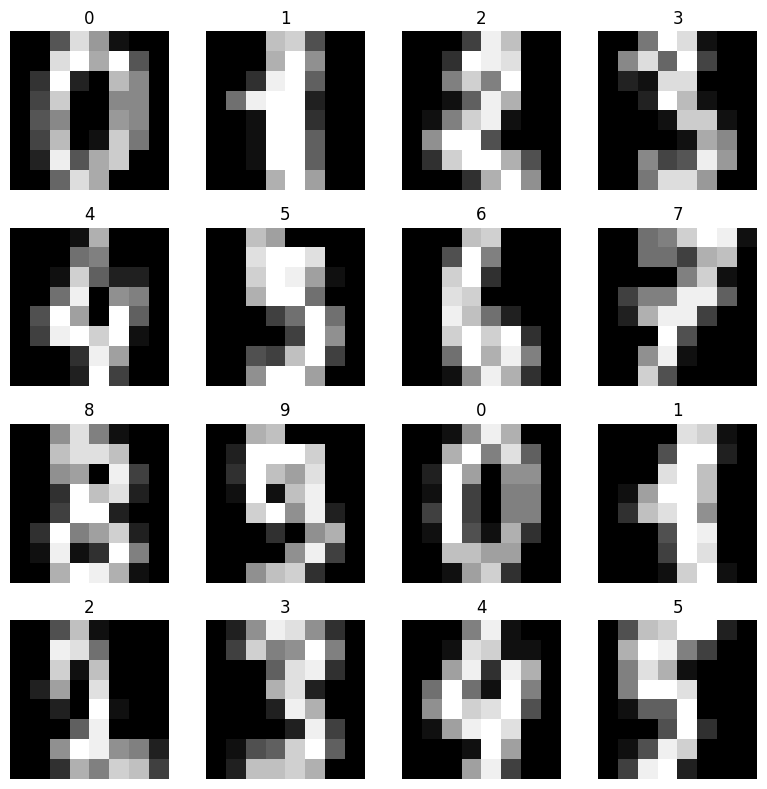

In [7]:
show_grid(X, y, 4, 4)

In [8]:
# Split into train and test
X_train, X_val = train_test_split(X, test_size=0.2, random_state=42, stratify=digits.target)
X_train.shape, X_val.shape

((1437, 8, 8, 1), (360, 8, 8, 1))

In [9]:
X.shape[1:]

(8, 8, 1)

In [10]:
# Building VAE
latent_dim = 8
# inp = Input(shape=(8,8,1))
inp = Input(shape=X.shape[1:])
x = layers.Flatten()(inp)

# Encoder
x = layers.Dense(32, activation='relu')(x)
x = layers.Dense(16, activation='relu')(x)

# VAE speciality
z_mean = layers.Dense(latent_dim, name='z_mean')(x)
z_log_var = layers.Dense(latent_dim, name='z_log_var')(x)

class Sampling(layers.Layer):
    def call(self, inputs):
        m, lv = inputs
        eps = tf.random.normal(shape=tf.shape(m))
        return m + tf.exp(0.5*lv)*eps

z = Sampling()([z_mean, z_log_var])

encoder = Model(inp, [z_mean, z_log_var, z], name='encoder')
encoder.summary()



Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 8, 8, 1)   │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 64)        │          0 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 32)        │      2,080 │ flatten[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 16)        │        528 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_mean (Dense)      │ (None, 8)         │        136 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_log_var (Dense)   │ (None, 8)         │        136 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sampling (Sampling) │ (None, 8)         │          0 │ z_mean[0][0],     │
│                     │                   │            │ z_log_var[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,880 (11.25 KB)

 Trainable params: 2,880 (11.25 KB)

 Non-trainable params: 0 (0.00 B)

In [11]:
# Decoder
latent_inputs = Input(shape=(latent_dim,))
x = layers.Dense(16, activation='relu')(latent_inputs)
x = layers.Dense(32, activation='relu')(x)
x = layers.Dense(64, activation='relu')(x)
x = layers.Reshape((8,8,1))(x)

decoder = Model(latent_inputs, x, name='decoder')
decoder.summary()

Model: "decoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 8)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 8, 8, 1)        │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,800 (10.94 KB)

 Trainable params: 2,800 (10.94 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:

class VAE(Model):
    def __init__(self, encoder, decoder):
        super().__init__()
        self.encoder, self.decoder = encoder, decoder
        self.total_loss_tracker = tf.keras.metrics.Mean(name="total_loss")
        self.recon_loss_tracker = tf.keras.metrics.Mean(name="recon_loss")
        self.kl_loss_tracker = tf.keras.metrics.Mean(name="kl_loss")

    @property
    def metrics(self): return [self.total_loss_tracker, self.recon_loss_tracker, self.kl_loss_tracker]

    def train_step(self, data):
        x = data[0] if isinstance(data, tuple) else data
        with tf.GradientTape() as tape:
            m, lv, z = self.encoder(x, training=True)
            logits = self.decoder(z, training=True) # x^ = logits
            recon = tf.nn.sigmoid_cross_entropy_with_logits(labels=x, logits=logits)
            recon_loss = tf.reduce_mean(tf.reduce_sum(recon, axis=[1,2,3]))
            kl = -0.5*tf.reduce_sum(1 + lv - tf.square(m) - tf.exp(lv), axis=1)
            kl_loss = tf.reduce_mean(kl)
            total = recon_loss + kl_loss
        grads = tape.gradient(total, self.trainable_variables)
        self.optimizer.apply_gradients(zip(grads, self.trainable_variables))
        self.total_loss_tracker.update_state(total)
        self.recon_loss_tracker.update_state(recon_loss)
        self.kl_loss_tracker.update_state(kl_loss)
        return {"total_loss": self.total_loss_tracker.result(),
                "recon_loss": self.recon_loss_tracker.result(),
                "kl_loss": self.kl_loss_tracker.result()}

    def test_step(self, data):
        x = data[0] if isinstance(data, tuple) else data
        m, lv, z = self.encoder(x, training=False)
        logits = self.decoder(z, training=False)
        recon = tf.nn.sigmoid_cross_entropy_with_logits(labels=x, logits=logits)
        recon_loss = tf.reduce_mean(tf.reduce_sum(recon, axis=[1,2,3]))
        kl = -0.5*tf.reduce_sum(1 + lv - tf.square(m) - tf.exp(lv), axis=1)
        kl_loss = tf.reduce_mean(kl)
        total = recon_loss + kl_loss
        self.total_loss_tracker.update_state(total)
        self.recon_loss_tracker.update_state(recon_loss)
        self.kl_loss_tracker.update_state(kl_loss)
        return {"total_loss": self.total_loss_tracker.result(),
                "recon_loss": self.recon_loss_tracker.result(),
                "kl_loss": self.kl_loss_tracker.result()}

vae = VAE(encoder, decoder)
vae.compile(optimizer=tf.keras.optimizers.Adam(1e-3))


In [13]:
history = vae.fit(X_train,
                  X_train,
                  validation_data=(X_val, X_val),
                  epochs=20,
                  batch_size=128,
                  verbose=2)

Epoch 1/20
12/12 - 11s - 919ms/step - kl_loss: 0.9607 - recon_loss: 45.5107 - total_loss: 46.4714 - val_kl_loss: 0.3934 - val_recon_loss: 44.9851 - val_total_loss: 45.3786
Epoch 2/20
12/12 - 1s - 105ms/step - kl_loss: 0.2301 - recon_loss: 44.6468 - total_loss: 44.8769 - val_kl_loss: 0.1229 - val_recon_loss: 44.4256 - val_total_loss: 44.5486
Epoch 3/20
12/12 - 0s - 25ms/step - kl_loss: 0.0776 - recon_loss: 44.2729 - total_loss: 44.3505 - val_kl_loss: 0.0483 - val_recon_loss: 44.1518 - val_total_loss: 44.2001
Epoch 4/20
12/12 - 0s - 22ms/step - kl_loss: 0.0324 - recon_loss: 44.0549 - total_loss: 44.0873 - val_kl_loss: 0.0221 - val_recon_loss: 43.9906 - val_total_loss: 44.0127
Epoch 5/20
12/12 - 0s - 17ms/step - kl_loss: 0.0154 - recon_loss: 43.9151 - total_loss: 43.9305 - val_kl_loss: 0.0121 - val_recon_loss: 43.8579 - val_total_loss: 43.8701
Epoch 6/20
12/12 - 0s - 26ms/step - kl_loss: 0.0087 - recon_loss: 43.7993 - total_loss: 43.8080 - val_kl_loss: 0.0076 - val_recon_loss: 43.7554 - v

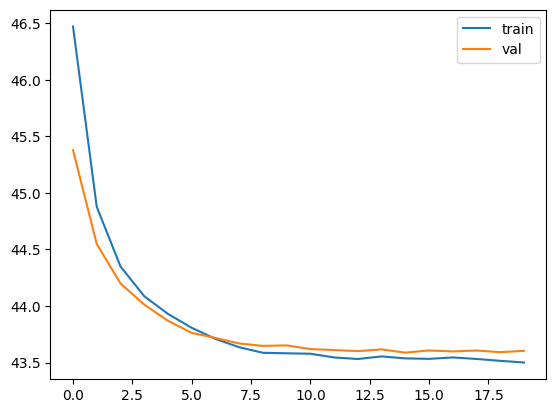

In [14]:
plt.plot(history.history['total_loss'], label='train')
plt.plot(history.history['val_total_loss'], label='val')
plt.legend()
plt.show()

In [15]:
def show_reconstructions(model, x, n=4):
    m, lv, z = model.encoder(x[:n], training=False)
    logits = model.decoder(z, training=False)
    x_rec = tf.sigmoid(logits).numpy()

    import matplotlib.pyplot as plt
    plt.figure(figsize=(2*n,4))
    for i in range(n):
        plt.subplot(2,n,i+1); plt.imshow(x[i,...,0], cmap='gray'); plt.axis('off')
        plt.subplot(2,n,n+i+1); plt.imshow(x_rec[i,...,0], cmap='gray'); plt.axis('off')
    plt.suptitle('Top: originals, Bottom: reconstructions'); plt.show()

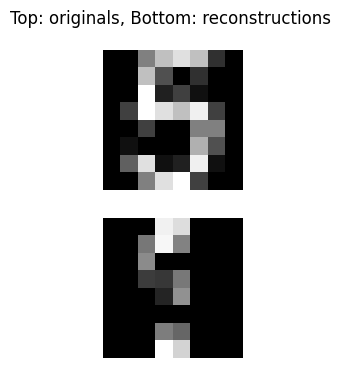

In [16]:
show_reconstructions(vae, X_val, n=1)

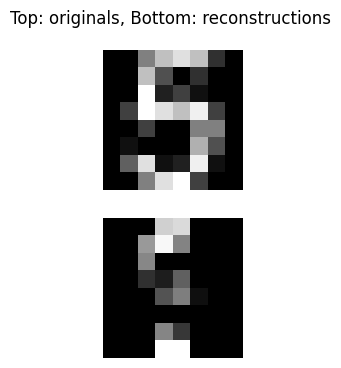

In [17]:
show_reconstructions(vae, X_val, n=1)